In [1]:
from pathlib import Path
import vtk
from pathlib import Path
from scipy.stats import multivariate_normal
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from scipy import io as scio
from scipy import stats as sci_stats
import pickle
import scipy.spatial as sp
from typing import Union,Dict,List
import copy
import sys
sys.path.append('../../scripts')
import gpa

In [8]:
path_to_processed_cohort = r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/gut_wd"
result_energies = r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/malefemale_pvals.mat"

In [88]:
def compute_center_of_mesh(mesh):
    centerOfMassFilter = vtk.vtkCenterOfMass()
    centerOfMassFilter.SetInputData(mesh)
    centerOfMassFilter.SetUseScalarsAsWeights(False)
    centerOfMassFilter.Update();
    center = centerOfMassFilter.GetCenter()
    return center



reader = vtk.vtkOBJReader()
num_of_points = 0
meshes_dict = {}
for path in tqdm(list(Path(path_to_processed_cohort).iterdir())):
    mesh_file = path / "head_affine_registered.obj"
    if not mesh_file.exists():
        continue
    reader.SetFileName(mesh_file)
    reader.Update()
    mesh = reader.GetOutput()
    points = mesh.GetPoints()
    center_of_mesh = np.array( compute_center_of_mesh(mesh) )
    num_of_points = points.GetNumberOfPoints()
    res_mesh = []
    for i in range(points.GetNumberOfPoints()):
        pt = points.GetPoint(i)
        res_mesh.append(list( np.array( pt) - center_of_mesh ))
    meshes_dict[str( mesh_file.parent.name ) ] = res_mesh

  0%|          | 0/768 [00:00<?, ?it/s]

In [89]:
def write_obj_2_file(obj,filename):
    f = open(filename,"wb")
    pickle.dump(obj,f)
    f.close()

def compute_descriptive_statistics(points):
    mean = np.mean(points, axis=0)
    std_dev = np.std(points, axis=0)
    # Add any other statistics you're interested in
    return mean, std_dev

def compute_outliers(meshes_dict: Union[Dict[str,np.ndarray],List[np.ndarray]]):
    
    stats = []
    index_sum=None
    if isinstance(meshes_dict,list):
        num_of_points = len( meshes_dict[0] )
        working_dict = list(zip(range(num_of_points),meshes_dict))
        
    else:
        num_of_points = len( list(meshes_dict.values())[0] )
        working_dict = list(meshes_dict.items())
            
    for i in tqdm(range(num_of_points)): # i in range of num_of_points
        index = []
        points = []
        #print (i, working_dict)
        for key, mesh_v in working_dict:
            index.append(key)
            points.append(mesh_v[i])
        
        df = pd.DataFrame( data = points, index=index, columns=['x','y','z'])
        
        indexes = (np.abs(sci_stats.zscore(df)) < 2).all(axis=1)
        
        if index_sum is None:
            index_sum = (~indexes).astype(int)
        else:
            index_sum += (~indexes).astype(int)
        df = df[indexes]
        stats.append(df.describe())
    
    return stats, index_sum

    

stats, index_sum = compute_outliers(meshes_dict)



  0%|          | 0/25680 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [90]:


meshes_dict_copy = copy.copy(meshes_dict)


#copy dict 
# for k,v in sorted(index_sum.items(), key=lambda x:x[1]):
#     if v > 1000:
#         meshes_dict_copy.pop(k)

In [92]:
#procrustes analysis

ref_mesh, aligned_meshes, shapes= gpa.gpa(meshes_dict_copy,max_iterations=100, threshold=1e-11)

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/767 [00:00<?, ?it/s]

Procrustes distance  489.84251989615535


  0%|          | 0/767 [00:00<?, ?it/s]

Procrustes distance  0.0008304998093270163


  0%|          | 0/767 [00:00<?, ?it/s]

Procrustes distance  1.408046846328839e-09


  0%|          | 0/767 [00:00<?, ?it/s]

Procrustes distance  2.387232118456047e-15


  0%|          | 0/768 [00:00<?, ?it/s]

In [93]:
#divide male to female
males = { k: v for k,v in shapes.items() if k.split("_")[1] == "M" }
females = { k: v for k,v in shapes.items() if k.split("_")[1] == "F" }

In [35]:
list(males.values())

[array([[-0.00152442, -0.00103094, -0.00960764],
        [-0.00170672, -0.00094902, -0.00961225],
        [ 0.00179428, -0.00128133, -0.00930293],
        ...,
        [-0.0028269 , -0.00353461, -0.00813283],
        [ 0.00057102,  0.00502545,  0.00376819],
        [-0.00379205,  0.0002111 , -0.00205725]]),
 array([[-1.43521813e-03, -7.45197408e-04, -9.65276017e-03],
        [-1.58357728e-03, -6.76668248e-04, -9.62370571e-03],
        [ 1.84907383e-03, -1.02974207e-03, -9.32881818e-03],
        ...,
        [-2.75694065e-03, -3.46692389e-03, -8.52494217e-03],
        [ 5.96197015e-04,  5.15650430e-03,  3.51509973e-03],
        [-3.87954957e-03, -4.33121336e-05, -2.02758216e-03]]),
 array([[-0.00138258, -0.00080101, -0.0096071 ],
        [-0.00151703, -0.000731  , -0.00958531],
        [ 0.00194487, -0.0012075 , -0.00931029],
        ...,
        [-0.00289669, -0.00333657, -0.00830781],
        [ 0.00063794,  0.00513125,  0.00357407],
        [-0.00381784, -0.00014604, -0.00202877]]),
 

In [105]:
# mann w
p_values = []

for i in tqdm(range(num_of_points)):
    pt_m = []
    pt_f = [] 
    for _,v in males.items():
        pt_m.append( v[i,:])
    for _,v in females.items():
        pt_f.append( v[i,:])
    
    pt_m = np.stack(pt_m)
    pt_f = np.stack(pt_f)
    ks_p_values = []
    for dim in range(3):
        #ks_statistic, ks_p_value = sci_stats.ttest_ind(pt_m[:, dim], pt_f[:, dim])
        ks_statistic, ks_p_value = sci_stats.ks_2samp(pt_m[:, dim], pt_f[:, dim])
        ks_p_values.append(ks_p_value)
    
    p_values.append(ks_p_values)
    
p_values =np.stack(p_values)    
    

  0%|          | 0/25680 [00:00<?, ?it/s]

In [107]:
#mean mesh
#iterate over faces 

res_array = (p_values > 0.005).any(axis=1)
polygons = mesh.GetPolys()
faces = []
# Iterate over the polygons to extract the faces
polygons.InitTraversal()
while True:
    faceIds = vtk.vtkIdList()
    if polygons.GetNextCell(faceIds):
        face = [faceIds.GetId(i) for i in range(faceIds.GetNumberOfIds())]
        faces.append(face)
    else:
        break
        
### compute colors and write to mat 
energies = []
for x in faces:
    en = 0 
    for p in x:
        en+= res_array[p]
    energies.append(en > 2)

scio.savemat(result_energies, {"energies": energies})


In [58]:
sci_stats.describe(pt_m)

DescribeResult(nobs=257, minmax=(array([-0.00402326, -0.0002907 , -0.0022925 ]), array([-0.00370584,  0.00042568, -0.00158211])), mean=array([-3.86582150e-03,  3.66400959e-05, -1.95511685e-03]), variance=array([3.23554824e-09, 2.11075970e-08, 1.65202954e-08]), skewness=array([ 0.19115522, -0.38555795,  0.21286069]), kurtosis=array([ 0.13646555, -0.85316163, -0.05541325]))

In [48]:
sci_stats.mannwhitneyu(pt_m,pt_f,alternative='two-sided')

MannwhitneyuResult(statistic=array([33009., 31872., 30943.]), pvalue=array([0.00220092, 0.0210793 , 0.09110944]))

In [90]:
(p_values > 0.05).any(axis=1)

array([ True, False,  True, ..., False,  True,  True])

In [80]:
sci_stats.ttest_ind(pt_f,pt_m)

Ttest_indResult(statistic=array([-2.90632391, -1.71053524, -1.82697721]), pvalue=array([0.00382754, 0.08781852, 0.06832923]))

In [60]:
sci_stats.describe(pt_f)

DescribeResult(nobs=221, minmax=(array([-0.00408094, -0.00026115, -0.00225687]), array([-0.00363991,  0.00025569, -0.00154528])), mean=array([-3.88119584e-03,  1.45153408e-05, -1.97510657e-03]), variance=array([3.42925965e-09, 1.84489499e-08, 1.15535705e-08]), skewness=array([ 0.37948141, -0.54847399,  0.40838322]), kurtosis=array([ 2.30303676, -0.93114081,  0.98017343]))

In [92]:
face

[24539, 17528, 17381]

In [5]:
import gpa

In [18]:
from importlib import reload
reload(gpa)

<module 'gpa' from '/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/scripts/notebooks/../scripts/gpa.py'>

In [94]:
errors_males = []
for _,sub in males.items():
    errors_males.append( gpa.procreustes_alignment(ref_mesh,sub[0])[1] )
    
errors_females = []
for _,sub in females.items():
    errors_females.append( gpa.procreustes_alignment(ref_mesh,sub[0])[1] )

array([[<AxesSubplot:title={'center':'0'}>]], dtype=object)

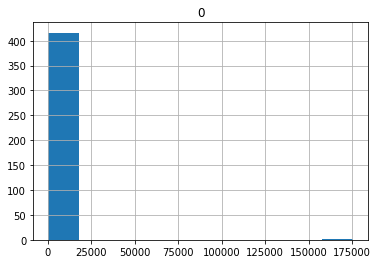

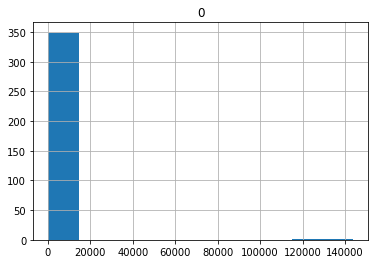

In [95]:
dfm = pd.DataFrame(errors_males,index=males.keys())
dfm.hist()
dff = pd.DataFrame(errors_females,index=females.keys())
dff.hist()

array([[<AxesSubplot:title={'center':'0'}>]], dtype=object)

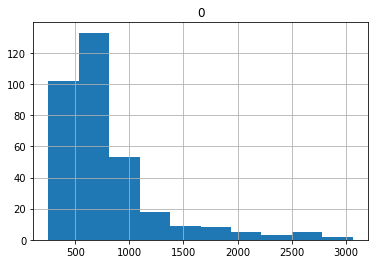

In [96]:
dff[dff<4000].hist()

In [100]:
np.percentile(dfm.values,95)

2312.1182548749052

In [99]:
dfm[dfm>np.percentile(dfm.values,95)].dropna()

,0
wt_M_82Z-CF112,2935.812110
wt_M_82Z-08081,3416.356329
wt_M_82Z-10327,2614.542120
wt_M_82Z-08332,10083.507786
wt_M_82Z-CG992,175412.393100
wt_M_82Z-CG149,2695.499866
wt_M_82Z-08082,2556.249008
wt_M_82Z-10329,2433.824467
wt_M_82Z-08222,2380.199297
wt_M_82Z-CE722,2541.818069


In [87]:
### remove outliers:
import os
keys = list((dff[dff>np.percentile(dff.values,99)].dropna()).index)


def remove(fn):
    try:
        os.remove(fn)
    except:
        pass

for k in tqdm(keys):
    
        folder = Path(path_to_processed_cohort) / k

        try:
            
            remove( folder / "affine_head.mat", )
            remove( folder / "coregistered_head.nii.gz" )
            remove( folder / "oriented_image.nii.gz" )
            remove( folder / "oriented_mask.nii.gz" )
            remove( folder / "bone_coregistration_mask.nii.gz" )
            remove( folder / "head_affine_registered.obj" )
            remove( folder / "nonlin_image.nii.gz" )
            remove( folder / "nl_transformation_params.txt" )
        except Exception as e:
            print(e)
            pass
        


  0%|          | 0/4 [00:00<?, ?it/s]

SAVE MALE_FEMALE COHORT

In [ ]:
males = { k: v for k,v in meshes_dict_copy.items() if k.split("_")[1] == "M" }
females = { k: v for k,v in meshes_dict_copy.items() if k.split("_")[1] == "F" }
o_f =   "/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/wt_cohorts_pts.pkl"
of = open(o_f,'wb')
pickle.dump({"M": males, "F": females},of)
of.close()